In [1]:
import numpy as np
import seaborn as sns
from z3 import *
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap, BoundaryNorm
import time
import requests
from bs4 import BeautifulSoup
from IPython.display import Markdown, display,IFrame,HTML,Image


### Shut the Box
Use a scissors to cut away one or more groups of orthogonally connected cells (squares) from the grid above. Any group you cut away must have at least one cell along the boundary of the grid. The remaining cells must be orthogonally connected and not have any holes. 
 It must be possible to fold along some of the grid lines so that the remaining cells form the six walls of a rectangular solid (the “box”). There may not be any overlapping cells in the box. 
 Some cells have been labeled with 
 arrows 
 . These cells are 
 not 
 part of the box, but instead point in the direction(s) of the nearest box cells (looking in that square’s row and column). 
 Some cells have been labeled with 
 numbers 
 . These cells 
 are 
 part of the box. A number indicates how many cells within one king’s move of that cell are a part of the box. (Including the numbered cell.) 
 When the box is assembled, each 
 grey circle 
 should be directly opposite 
 1 
 another grey circle. Each 
 gray square 
 should be orthogonally adjacent to (and on the same face as) another gray square. 
 Once you have assembled the box, compute, on each face, the sum of the numbered cells. The answer to this puzzle is the 
 product 
 of these six sums. 
 An example grid can be seen 
 here 
 . Pictures of the solved region and assembled box for the example grid can be seen 
 here 
 . 
 (That is, the line segment connecting “opposite” circles should be orthogonal to the faces containing them.)

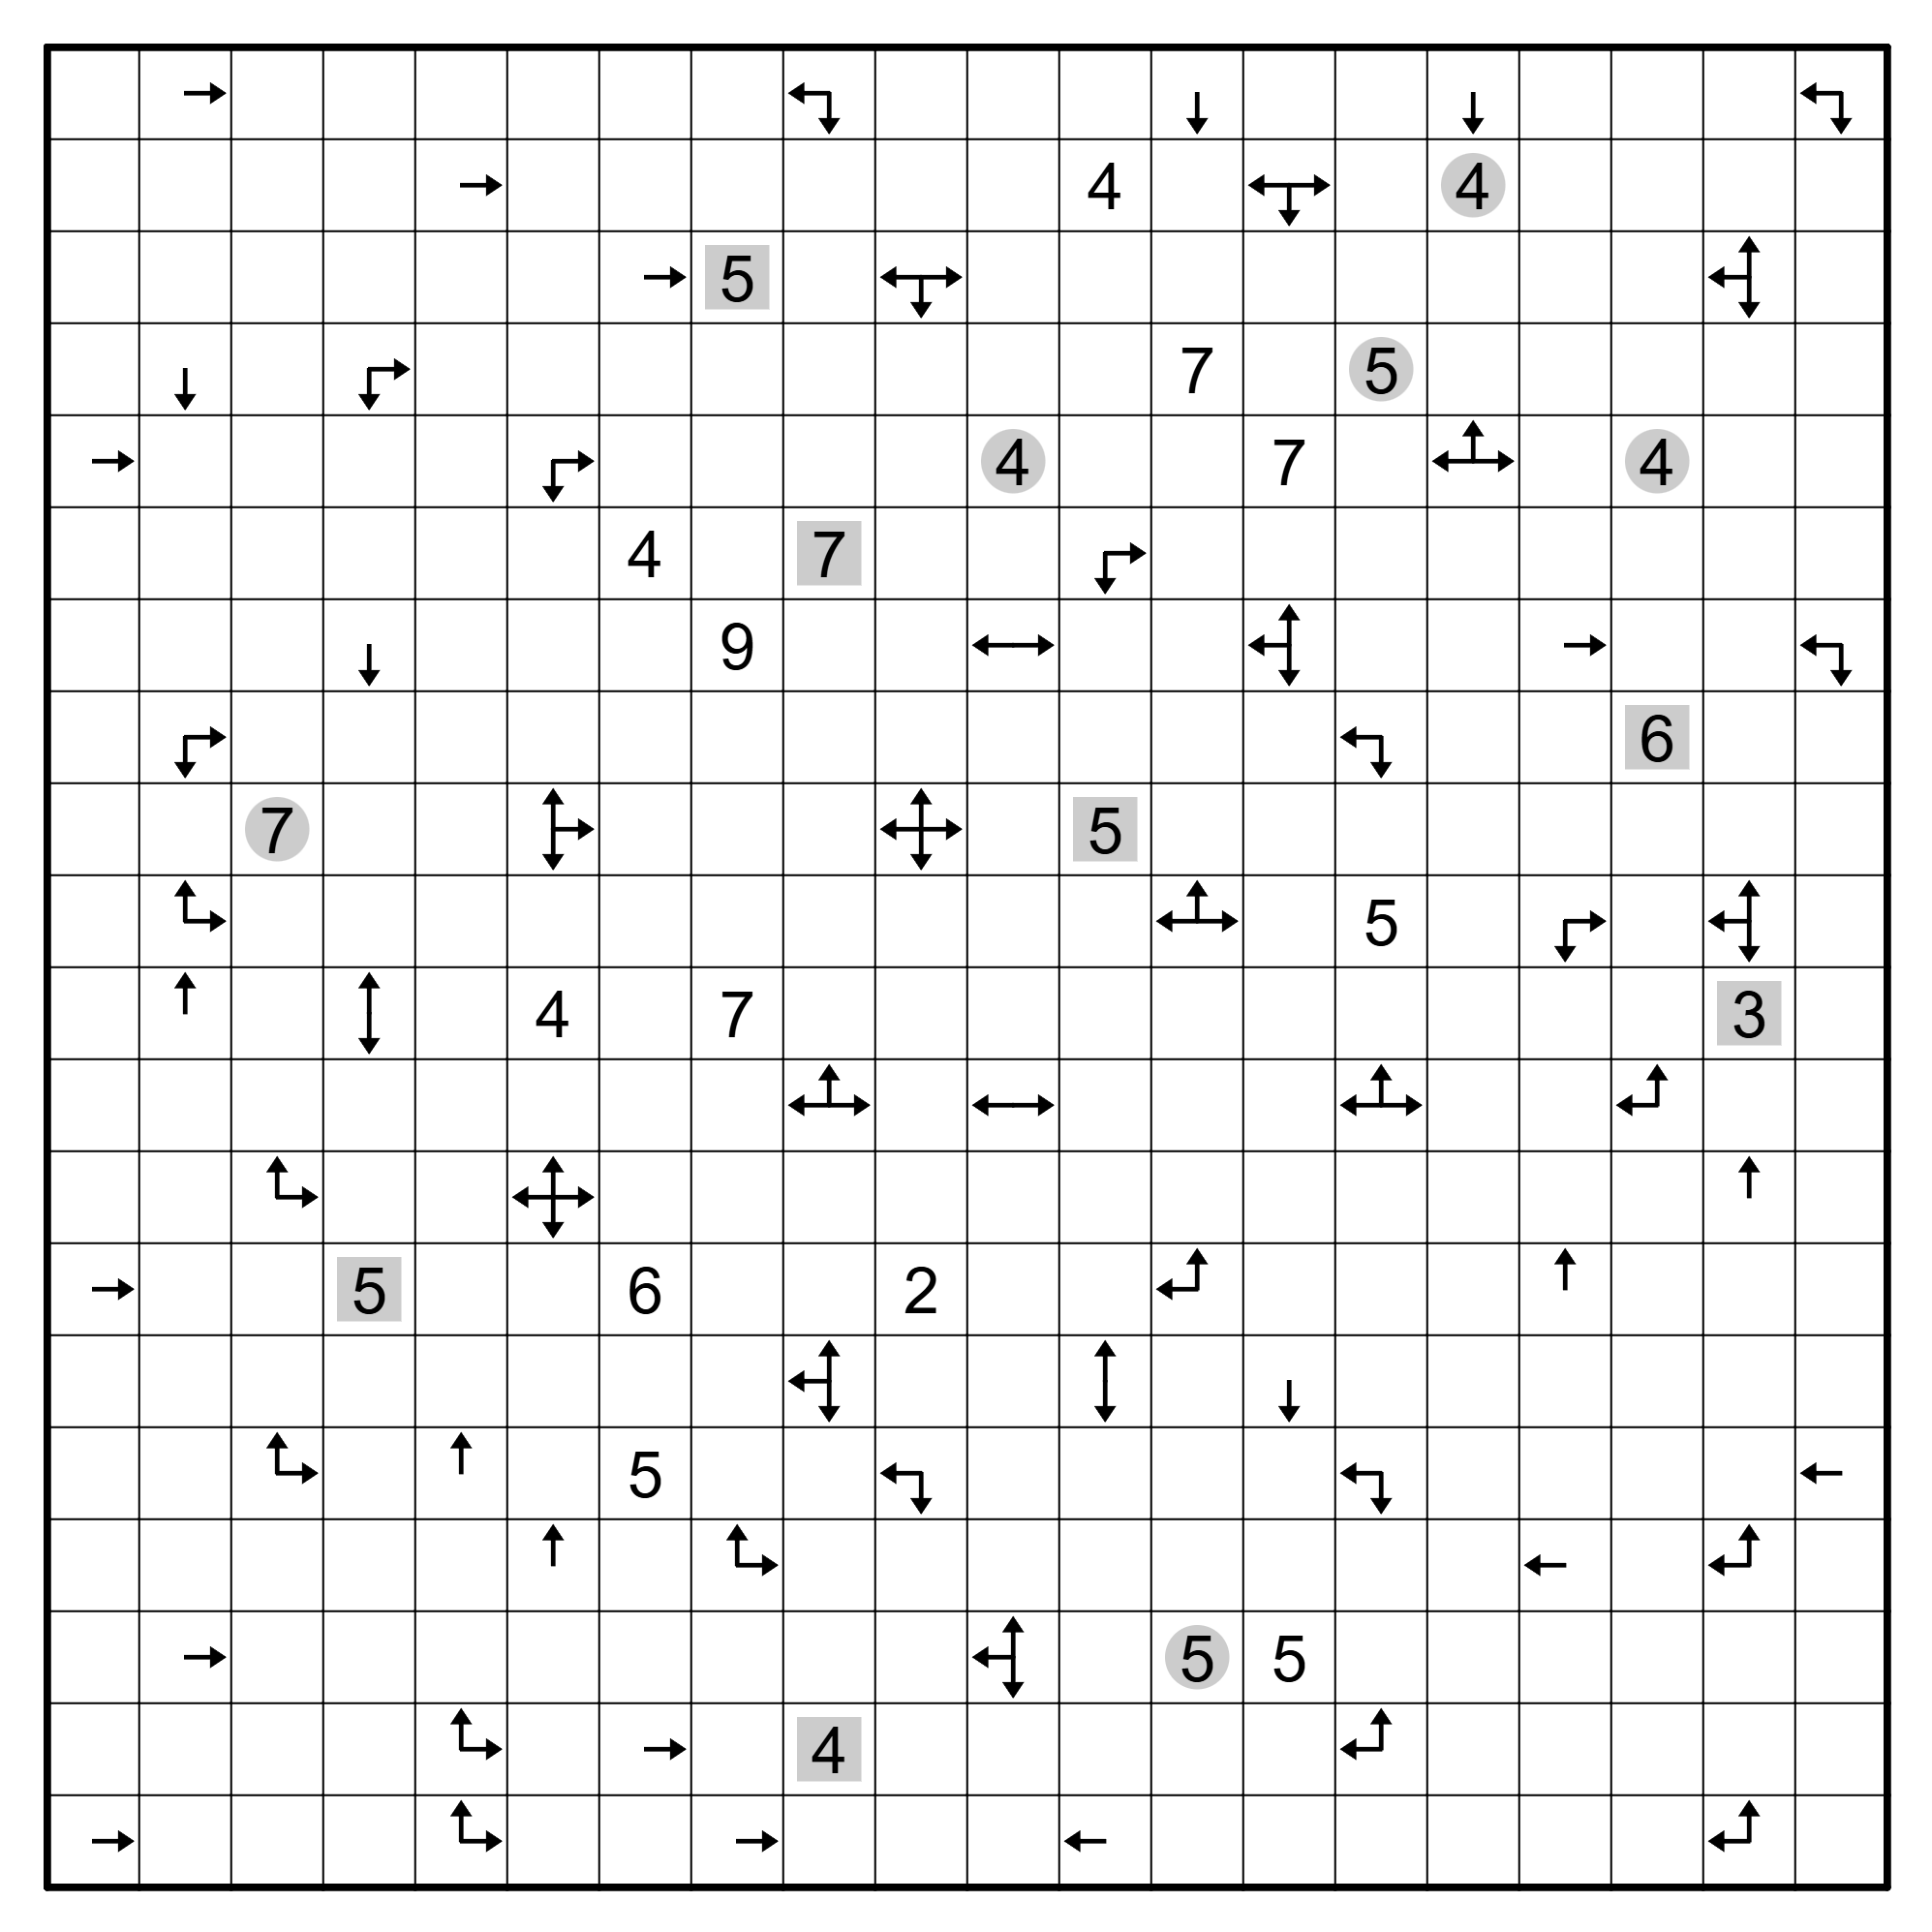

In [35]:
url='https://www.janestreet.com/puzzles/shut-the-box-index/'
res = requests.get(url)
soup = BeautifulSoup(res.content, 'html.parser')
y =[text for text in soup.body.stripped_strings]
#display([(i,j) for i,j in enumerate(y)])
display(Markdown("### "+y[13]+"\n"+" \n ".join(y[16:44])))
display(Image('https://www.janestreet.com/puzzles/shut-the-box.png',width=400))

In [3]:
numbers = np.array([   [0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0],
                       [0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 4, 0, 0, 0, 4, 0, 0, 0, 0],
                       [0, 0, 0, 0, 0, 0, 0, 5, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0],
                       [0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 7, 0, 5, 0, 0, 0, 0, 0],
                       [0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 4, 0, 0, 7, 0, 0, 0, 4, 0, 0],
                       [0, 0, 0, 0, 0, 0, 4, 0, 7, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0],
                       [0, 0, 0, 0, 0, 0, 0, 9, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0],
                       [0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 6, 0, 0],
                       [0, 0, 7, 0, 0, 0, 0, 0, 0, 0, 0, 5, 0, 0, 0, 0, 0, 0, 0, 0],
                       [0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 5, 0, 0, 0, 0, 0],
                       [0, 0, 0, 0, 0, 4, 0, 7, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 3, 0],
                       [0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0],
                       [0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0],
                       [0, 0, 0, 5, 0, 0, 6, 0, 0, 2, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0],
                       [0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0],
                       [0, 0, 0, 0, 0, 0, 5, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0],
                       [0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0],
                       [0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 5, 5, 0, 0, 0, 0, 0, 0],
                       [0, 0, 0, 0, 0, 0, 0, 0, 4, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0],
                       [0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0]])


arrows = np.array([[ 0,  2,  0,  0,  0,  0,  0,  0, 12,  0,  0,  0,  4,  0,  0,  4,  0,  0,  0, 12],
                   [ 0,  0,  0,  0,  2,  0,  0,  0,  0,  0,  0,  0,  0, 14,  0,  0,  0,  0,  0,  0],
                   [ 0,  0,  0,  0,  0,  0,  2,  0,  0, 14,  0,  0,  0,  0,  0,  0,  0,  0, 13,  0],
                   [ 0,  4,  0,  6,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0],
                   [ 2,  0,  0,  0,  0,  6,  0,  0,  0,  0,  0,  0,  0,  0,  0, 11,  0,  0,  0,  0],
                   [ 0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  6,  0,  0,  0,  0,  0,  0,  0,  0],
                   [ 0,  0,  0,  4,  0,  0,  0,  0,  0,  0, 10,  0,  0, 13,  0,  0,  2,  0,  0, 12],
                   [ 0,  6,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0, 12,  0,  0,  0,  0,  0],
                   [ 0,  0,  0,  0,  0,  7,  0,  0,  0, 15,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0],
                   [ 0,  3,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0, 11,  0,  0,  0,  6,  0, 13,  0],
                   [ 0,  1,  0,  5,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0],
                   [ 0,  0,  0,  0,  0,  0,  0,  0, 11,  0, 10,  0,  0,  0, 11,  0,  0,  9,  0,  0],
                   [ 0,  0,  3,  0,  0, 15,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  1,  0],
                   [ 2,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  9,  0,  0,  0,  1,  0,  0,  0],
                   [ 0,  0,  0,  0,  0,  0,  0,  0, 13,  0,  0,  5,  0,  4,  0,  0,  0,  0,  0,  0],
                   [ 0,  0,  3,  0,  1,  0,  0,  0,  0, 12,  0,  0,  0,  0, 12,  0,  0,  0,  0,  8],
                   [ 0,  0,  0,  0,  0,  1,  0,  3,  0,  0,  0,  0,  0,  0,  0,  0,  8,  0,  9,  0],
                   [ 0,  2,  0,  0,  0,  0,  0,  0,  0,  0, 13,  0,  0,  0,  0,  0,  0,  0,  0,  0],
                   [ 0,  0,  0,  0,  3,  0,  2,  0,  0,  0,  0,  0,  0,  0,  9,  0,  0,  0,  0,  0],
                   [ 2,  0,  0,  0,  3,  0,  0,  2,  0,  0,  0,  8,  0,  0,  0,  0,  0,  0,  9,  0]]
                  )

color_grid = np.array([[0, 0, 0, 0, 0, 0, 1, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 1, 0],
                         [0, 0, 0, 0, 0, 0, 0, 1, 1, 0, 1, 1, 0, 0, 0, 1, 1, 1, 1, 1],
                         [0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 1, 1, 0, 1, 1, 0, 1, 0, 0],
                         [0, 0, 0, 0, 0, 0, 0, 1, 1, 0, 1, 1, 1, 1, 1, 0, 0, 1, 1, 1],
                         [0, 0, 0, 0, 0, 0, 0, 0, 1, 1, 1, 0, 1, 1, 0, 0, 0, 1, 0, 1],
                         [0, 0, 0, 0, 0, 0, 1, 1, 1, 0, 0, 0, 1, 1, 0, 0, 0, 1, 0, 0],
                         [0, 0, 0, 0, 0, 0, 1, 1, 1, 1, 0, 1, 1, 0, 0, 0, 0, 1, 1, 0],
                         [0, 0, 1, 1, 1, 1, 1, 1, 1, 0, 0, 1, 1, 1, 0, 0, 0, 1, 1, 1],
                         [0, 1, 1, 1, 0, 0, 1, 1, 0, 0, 0, 1, 1, 1, 1, 1, 0, 1, 1, 0],
                         [0, 0, 1, 1, 0, 1, 1, 1, 1, 0, 0, 1, 0, 1, 1, 0, 0, 1, 0, 0],
                         [0, 0, 0, 0, 0, 1, 1, 1, 1, 1, 0, 1, 0, 0, 0, 0, 1, 1, 1, 0],
                         [0, 0, 1, 1, 0, 0, 0, 1, 0, 1, 0, 1, 1, 0, 0, 0, 1, 0, 0, 0],
                         [0, 0, 0, 1, 0, 0, 0, 1, 0, 0, 0, 1, 1, 0, 0, 0, 0, 0, 0, 0],
                         [0, 0, 0, 1, 1, 0, 1, 1, 1, 1, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0],
                         [0, 0, 0, 1, 1, 1, 1, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0],
                         [0, 0, 0, 0, 0, 0, 1, 1, 1, 0, 0, 1, 1, 0, 0, 0, 0, 0, 0, 0],
                         [0, 0, 0, 0, 0, 0, 0, 0, 1, 1, 1, 1, 1, 0, 0, 0, 0, 0, 0, 0],
                         [0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 1, 1, 1, 0, 0, 0, 0, 0],
                         [0, 0, 0, 0, 0, 0, 0, 0, 1, 1, 1, 0, 0, 1, 0, 0, 0, 0, 0, 0],
                         [0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0]])


In [4]:
numbers_test = np.array([
[0, 0, 0, 0, 0, 0, 0, 0],
[0, 0, 0, 5, 0, 0, 0, 0],
[2, 5, 0, 0, 0, 4, 0, 0],
[0, 0, 0, 0, 0, 0, 0, 2],
[2, 0, 0, 5, 0, 0, 0, 0],
[0, 0, 0, 0, 0, 0, 0, 0],
[0, 0, 0, 6, 6, 0, 0, 0],
[0, 4, 0, 0, 0, 4, 0, 0],
])

arrows_test = np.array([   [0,0,4,0,0,0,4,0],
                            [0,0,0,0,12,0,0,4],
                            [0,0,0,0,0,0,0,0],       
                            [0,0,0,0,11,0,0,0],   
                            [0,0,0,0,0,0,0,0], 
                            [0,0,7,0,0,0,4,1],  
                            [4,0,0,0,0,0,0,0],    
                            [0,0,0,0,0,0,0,0]                           
                           ])

circ_sq_test = np.array([  [0, 0, 0, 0, 0, 0, 0, 0],
                         [0, 0, 0, 0, 0, 0, 0, 0],                           
                         [0, 1, 0, 0, 0, 0, 0, 0],    
                         [0, 0, 0, 0, 0, 0, 0, 1],
                         [0, 0, 0, 2, 0, 0, 0, 0],
                         [0, 0, 0, 0, 0, 0, 0, 0],
                         [0, 0, 0, 0, 2, 0, 0, 0],
                         [0, 2, 0, 0, 0, 2, 0, 0]])


color_grid_test  = np.array([ [0, 0, 0, 0, 0, 0, 0, 0],
                               [0, 0, 1, 1, 0, 0, 0, 0],
                               [1, 1, 1, 1, 1, 1, 0, 0],
                               [0, 0, 1, 1, 0, 1, 1, 1],
                               [1, 1, 1, 1, 0, 0, 0, 0],
                               [0, 0, 0, 1, 0, 0, 0, 0],
                               [0, 0, 1, 1, 1, 1, 1, 0],
                               [1, 1, 1, 1, 0, 1, 0, 0]])



In [10]:
def print_grid(numbers_test,arrows_test,color_grid):

    # ----------------------------
    # ARROW BIT DECODING
    # ----------------------------
    BITS = {"U":1, "R":2, "D":4, "L":8}
    
    def decode_arrows(mask):
        arrows = ""
        if mask & BITS["U"]: arrows += "↑"
        if mask & BITS["R"]: arrows += "→"
        if mask & BITS["D"]: arrows += "↓"
        if mask & BITS["L"]: arrows += "←"
        return arrows
    
    # ----------------------------
    # CREATE TEXT ANNOTATION GRID
    # ----------------------------
    annotations = np.empty(numbers_test.shape, dtype=object)
    
    for r in range(numbers_test.shape[0]):
        for c in range(numbers_test.shape[1]):
            if numbers_test[r, c] != 0:           # show number
                annotations[r, c] = str(numbers_test[r, c])
            elif arrows_test[r, c] != 0:          # show arrow(s)
                annotations[r, c] = decode_arrows(arrows_test[r, c])
            else:
                annotations[r, c] = ""            # empty cell
    
       # ----------------------------
    # CUSTOM COLORMAP (white → 6 colors)
    # ----------------------------
    cmap = ListedColormap([
        "#FFFFFF",  # 0 → white
        "#1f77b4",  # 1 → blue
        "#ff7f0e",  # 2 → orange
        "#2ca02c",  # 3 → green
        "#d62728",  # 4 → red
        "#9467bd",  # 5 → purple
        "#8c564b",  # 6 → brown
    ])
    
    
    # ----------------------------
    # PLOT
    # ----------------------------
    if numbers_test.shape[0] == 20:
        grid_size = 8
    else:
        grid_size =3
    
    plt.figure(figsize=(grid_size,
                        grid_size))
    ax = sns.heatmap(
        color_grid,
        annot=annotations,
        fmt="",
        cmap=cmap,
        linewidths=2,
        linecolor="k",
        cbar=False     #  removed color bar
    )
    
    plt.tight_layout()
    plt.show()

def cuboids_with_surface_area(target_area):
    """
    Finds all positive-integer cuboids (a, b, c)
    such that 2(ab + bc + ac) = target_area.

    Returns a list of tuples (a, b, c).
    """
    solutions = []
    for a in range(1, target_area + 1):
        for b in range(a, target_area + 1):      # start at a to avoid permutations
            for c in range(b, target_area + 1):  # start at b to avoid permutations
                if 2 * (a*b + b*c + a*c) == target_area:
                    solutions.append((a, b, c))
    return solutions

In [55]:
def neigh(x,y,N):
    return [(i+x,j+y) for i,j in [(-1,0),(0,-1),(1,0),(0,1)] if i+x >=0 and i+x <N and j+y >=0 and j+y <N]

def king(x,y,N):
    return [(i+x,j+y) for i,j in [(-1,0),(0,-1),(1,0),(0,1),(-1,-1),(1,-1),(-1,1),(1,1),(0,0)] if i+x >=0 and i+x <N and j+y >=0 and j+y <N]


def solve_grid (numbers,arrows,colour_grid):
    start = time.time()
    N = numbers.shape[0]
    #set up the solver and variables.
    s = Tactic("default").solver()

    # solution grid with 0 for missing and 1 for included
    X = np.array(IntVector("x",N**2),dtype=object).reshape((N,N))
    s += [And(e>=0,e<=1) for (i,j),e in np.ndenumerate(X)]
    
    #test answer
    s+= [X[i,j] == int(e) for (i,j),e in np.ndenumerate(colour_grid)]
    
    # no holes
    s += [Implies(e == 0,Or([X[k,j]==0 for k,j in neigh(i,j,N)])) for (i,j),e in np.ndenumerate(X) if (i !=0) and (i!=N-1) and (j!=0) and (j!=N-1) ]

    # arrow and number
    s+= [Implies(int(e) != 0,X[i,j] ==1) for (i,j),e in np.ndenumerate(numbers)]
    s+= [Implies(int(e) != 0,X[i,j] ==0) for (i,j),e in np.ndenumerate(arrows)]

    s+= [Implies(int(e) > 0,Sum([X[k,l] for k,l in king(i,j,N)]) == e) for (i,j),e in np.ndenumerate(numbers)]
    
    # ensure net can form valid cuboid
    s+= Sum([e for (i,j),e in np.ndenumerate(X)]) == np.sum(colour_grid)

   # ==============================================================
    # CONNECTIVITY ONLY — all filled cells form ONE connected region
    # ==============================================================

    # Root indicator
    R = np.array(IntVector('r', N*N), dtype=object).reshape(N, N)
    s += [Or(R[i,j] == 0, R[i,j] == 1) for (i,j),_ in np.ndenumerate(R)]

    # Distance labels
    D = np.array(IntVector('d', N*N), dtype=object).reshape(N, N)
    s += [And(D[i,j] >= 0, D[i,j] <= N*N)
          for (i,j),_ in np.ndenumerate(D)]

    # Exactly one root among filled cells
    root_flags = [(R[i,j] == 1, 1)
                  for (i,j),_ in np.ndenumerate(R)]
    s += PbEq(root_flags, 1)

    # Root must be filled and have distance 0
    for (i,j),_ in np.ndenumerate(R):
        s += Implies(R[i,j] == 1, X[i,j] == 1)
        s += Implies(R[i,j] == 1, D[i,j] == 0)

    # Non-root filled cells must have positive distance
    for (i,j),_ in np.ndenumerate(X):
        s += Implies(And(X[i,j] == 1, R[i,j] == 0), D[i,j] >= 1)

    # Connectivity: every non-root filled cell must have at least
    # one filled neighbour with smaller distance
    for i in range(N):
        for j in range(N):
            smaller = [And(X[k,l] == 1, D[k,l] < D[i,j])
                       for (k,l) in neigh(i,j,N)]
            s += Implies(
                    And(X[i,j] == 1, R[i,j] == 0),
                    Or(*smaller)
                )


   
    # ==============================================================
    # ARROW CONSTRAINTS: nearest filled cell along each direction
    # ==============================================================
    
    DIRS = {
        1: (-1, 0),  # up
        2: (0,  1),  # right
        4: (1,  0),  # down
        8: (0, -1)   # left
    }
    
    # A large constant for "infinite distance"
    INF = 21
    
    for (i,j), arrow in np.ndenumerate(arrows):
        if arrow == 0:
            continue  # skip non-arrow cells
    
        # Distance variables for 4 directions
        Ddir = {bit: Int(f"D_{i}_{j}_{bit}") for bit in DIRS}
    
        # Each D is between 1 and INF
        for bit in DIRS:
            s += And(Ddir[bit] >= 1, Ddir[bit] <= INF)
    
        # For each direction, encode distance to first filled cell
        for bit, (di, dj) in DIRS.items():
            # Candidate distances: 1,2,3,...
            dist_constraints = []
            for step in range(1, N+1):
                ni = i + di * step
                nj = j + dj * step
                if not (0 <= ni < N and 0 <= nj < N):
                    continue
    
                # Check intermediate cells
                between = []
                for t in range(1, step):
                    bi = i + di * t
                    bj = j + dj * t
                    between.append(X[bi,bj] == 0)
    
                # If filled at step and all between empty → D = step
                dist_constraints.append(
                    And(X[ni,nj] == 1, *between, Ddir[bit] == step)
                )
    
            # If no filled cell along this ray → distance = INF
            s += Or(*dist_constraints, Ddir[bit] == INF)
    
        # The minimal direction distance
        d_min = Int(f"dmin_{i}_{j}")
        s += And(d_min >= 1, d_min <= INF)
    
        # d_min = minimum of distances
        for bit in DIRS:
            s += d_min <= Ddir[bit]
    
        # At least one direction achieves minimum
        s += Or(*[Ddir[bit] == d_min for bit in DIRS])
    
        # Match arrow bits
        for bit in DIRS:
            if arrow & bit:
                # This direction must be minimal
                s += Ddir[bit] == d_min
            else:
                # This direction must NOT be minimal
                s += Ddir[bit] > d_min

    
    print("setup done in {:.2f} seconds".format(time.time()-start))    
    counter = 0
    while s.check() == sat:
        counter += 1
        m = s.model()
        evalu = np.vectorize(lambda x:m.evaluate(x).as_long())
        result_x =  evalu(X)
        print_grid(numbers,arrows,result_x)
        print(result_x,np.sum(result_x),cuboids_with_surface_area(np.sum(result_x)))
        print("Took {:.4f} seconds".format(time.time()- start))
        s+=Or([e!=result_x[i,j] for (i,j),e in np.ndenumerate(X)]     )
    print("DONE",counter,"results","Took {:.4f} seconds".format(time.time()- start))


setup done in 0.21 seconds


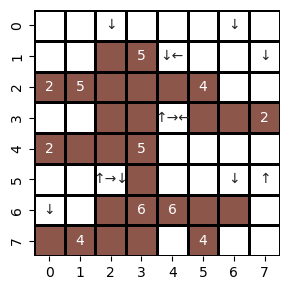

[[0 0 0 0 0 0 0 0]
 [0 0 1 1 0 0 0 0]
 [1 1 1 1 1 1 0 0]
 [0 0 1 1 0 1 1 1]
 [1 1 1 1 0 0 0 0]
 [0 0 0 1 0 0 0 0]
 [0 0 1 1 1 1 1 0]
 [1 1 1 1 0 1 0 0]] 28 [(1, 2, 4)]
Took 0.6743 seconds


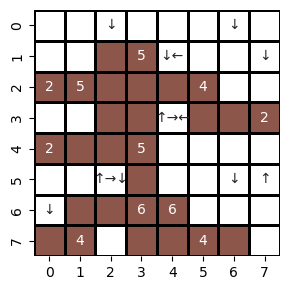

[[0 0 0 0 0 0 0 0]
 [0 0 1 1 0 0 0 0]
 [1 1 1 1 1 1 0 0]
 [0 0 1 1 0 1 1 1]
 [1 1 1 1 0 0 0 0]
 [0 0 0 1 0 0 0 0]
 [0 1 1 1 1 0 0 0]
 [1 1 0 1 1 1 1 0]] 28 [(1, 2, 4)]
Took 1.0898 seconds


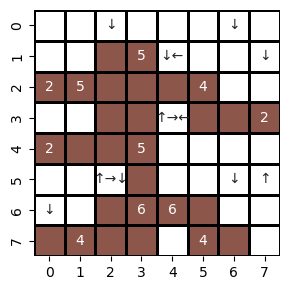

[[0 0 0 0 0 0 0 0]
 [0 0 1 1 0 0 0 0]
 [1 1 1 1 1 1 0 0]
 [0 0 1 1 0 1 1 1]
 [1 1 1 1 0 0 0 0]
 [0 0 0 1 0 0 0 0]
 [0 0 1 1 1 1 0 0]
 [1 1 1 1 0 1 1 0]] 28 [(1, 2, 4)]
Took 1.5336 seconds
DONE 3 results Took 2.2221 seconds


In [53]:
solve_grid(numbers_test,arrows_test,color_grid_test)

setup done in 2.32 seconds


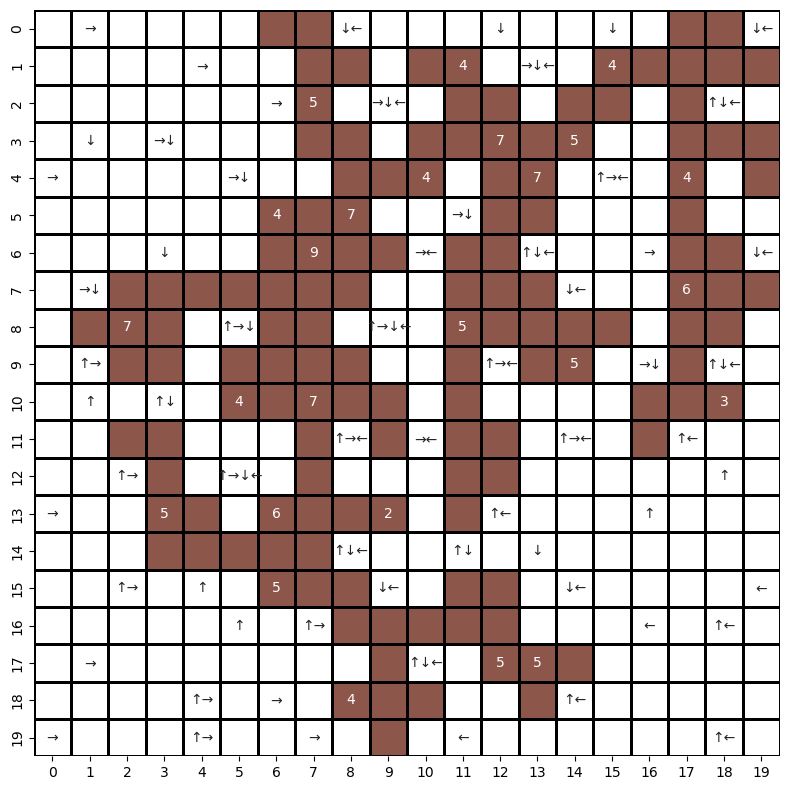

[[0 0 0 0 0 0 1 1 0 0 0 0 0 0 0 0 0 1 1 0]
 [0 0 0 0 0 0 0 1 1 0 1 1 0 0 0 1 1 1 1 1]
 [0 0 0 0 0 0 0 1 0 0 0 1 1 0 1 1 0 1 0 0]
 [0 0 0 0 0 0 0 1 1 0 1 1 1 1 1 0 0 1 1 1]
 [0 0 0 0 0 0 0 0 1 1 1 0 1 1 0 0 0 1 0 1]
 [0 0 0 0 0 0 1 1 1 0 0 0 1 1 0 0 0 1 0 0]
 [0 0 0 0 0 0 1 1 1 1 0 1 1 0 0 0 0 1 1 0]
 [0 0 1 1 1 1 1 1 1 0 0 1 1 1 0 0 0 1 1 1]
 [0 1 1 1 0 0 1 1 0 0 0 1 1 1 1 1 0 1 1 0]
 [0 0 1 1 0 1 1 1 1 0 0 1 0 1 1 0 0 1 0 0]
 [0 0 0 0 0 1 1 1 1 1 0 1 0 0 0 0 1 1 1 0]
 [0 0 1 1 0 0 0 1 0 1 0 1 1 0 0 0 1 0 0 0]
 [0 0 0 1 0 0 0 1 0 0 0 1 1 0 0 0 0 0 0 0]
 [0 0 0 1 1 0 1 1 1 1 0 1 0 0 0 0 0 0 0 0]
 [0 0 0 1 1 1 1 1 0 0 0 0 0 0 0 0 0 0 0 0]
 [0 0 0 0 0 0 1 1 1 0 0 1 1 0 0 0 0 0 0 0]
 [0 0 0 0 0 0 0 0 1 1 1 1 1 0 0 0 0 0 0 0]
 [0 0 0 0 0 0 0 0 0 1 0 0 1 1 1 0 0 0 0 0]
 [0 0 0 0 0 0 0 0 1 1 1 0 0 1 0 0 0 0 0 0]
 [0 0 0 0 0 0 0 0 0 1 0 0 0 0 0 0 0 0 0 0]] 136 [(1, 2, 22), (2, 2, 16), (2, 4, 10), (2, 6, 7), (3, 4, 8)]
Took 2.9681 seconds
DONE 1 results Took 3.0172 seconds


In [43]:
solve_grid (numbers,arrows,color_grid)

### Shut the Box
The diagram above is shaded to show the cells that remain, and which can be foldified to form a 2×6×7 box. The product of the ‘‘sum of the numbered cells’’ values for the six faces is 
 16414860 
 . 
 Congrats to everyone who assembled the box!

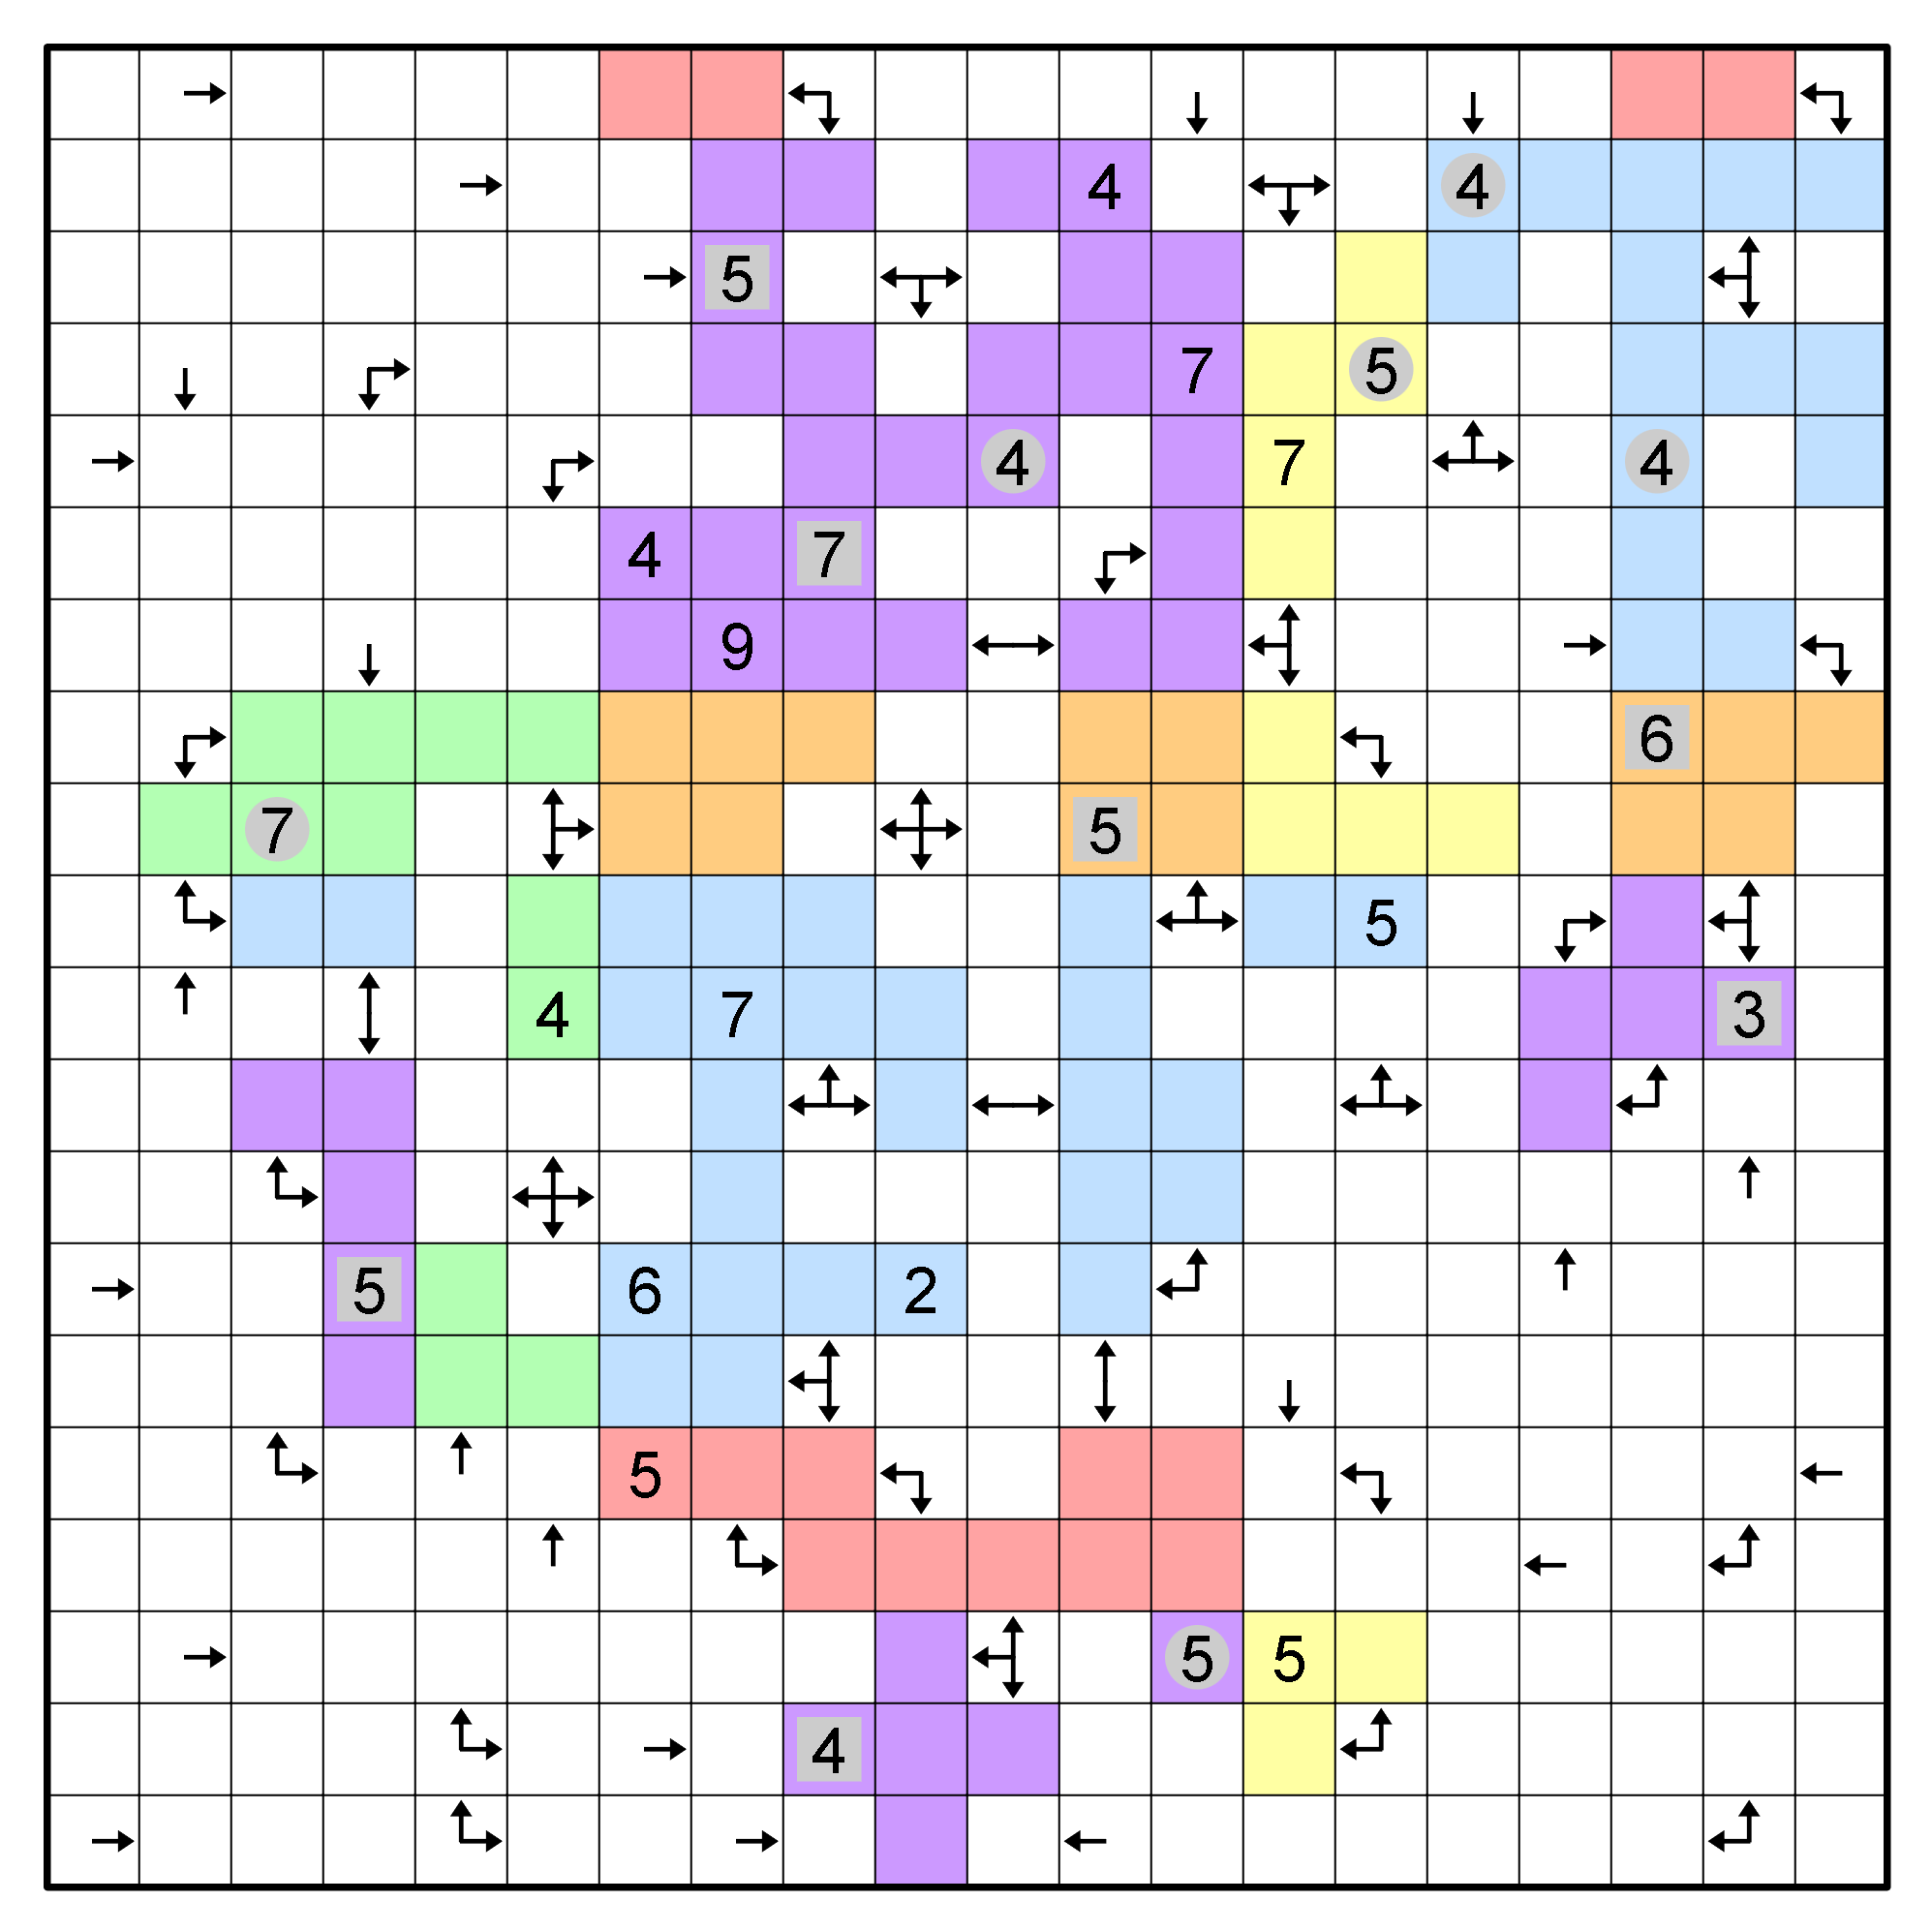

In [47]:
url='https://www.janestreet.com/puzzles/shut-the-box-solution/'
res = requests.get(url)
soup = BeautifulSoup(res.content, 'html.parser')
y =[text for text in soup.body.stripped_strings]
#display([(i,j) for i,j in enumerate(y)])
display(Markdown("### "+y[13]+"\n"+" \n ".join(y[16:20])))
display(Image('https://www.janestreet.com/puzzles/shut-the-box-sol.png',width=400))